In [2]:
import pandas as pd
from matplotlib import pyplot as plt

In [3]:
df = pd.read_csv('imbalanced_data.csv')
df.head()

,Unnamed: 0,content,score
0,0,v.good,5
1,1,always gets disconnected,1
2,2,good,4
3,3,Nice 👍,5
4,4,nice,5


# Remove Broken Data

In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  3000 non-null   int64 
 1   content     2999 non-null   object
 2   score       3000 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 70.4+ KB
None


In [5]:
df.drop('Unnamed: 0', axis=1, inplace=True)

In [6]:
print(df.isnull().sum())
df.dropna(subset=['content'], inplace=True)

content    1
score      0
dtype: int64


In [7]:
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)

265


In [8]:
# check non alphabetical words
from collections import Counter
def get_non_alpha_words(text):
  words = str(text).split()
  non_alpha = [word for word in words if not word.isalpha()]
  return non_alpha

all_non_alpha_words = []
for content in df['content']:
  all_non_alpha_words.extend(get_non_alpha_words(content))

non_alpha_counts = Counter(all_non_alpha_words)
print("Words with non-alphabetical characters:")
print(non_alpha_counts.most_common(50))

Words with non-alphabetical characters:
[("it's", 176), ("don't", 123), ('app.', 113), ("I'm", 94), ("can't", 91), ("It's", 85), ('.', 81), ('game.', 74), ('chess.', 67), (',', 67), ("doesn't", 55), ('1', 50), ('app,', 49), ('5', 49), ('2', 44), ("I've", 43), ('it.', 41), ('game,', 41), ('👍', 33), ('3', 33), ('10', 32), ('time.', 31), ("didn't", 24), ('free.', 24), ('chess,', 23), ('games.', 21), ('4', 21), ('ads.', 21), ('me.', 21), ('puzzles,', 21), ('now.', 20), ("you're", 20), ('this.', 20), ('it,', 19), ('app!', 19), ('games,', 18), ('free,', 18), ("that's", 17), ("won't", 17), ("Can't", 16), ('out.', 15), ('...', 15), ('&', 15), ('lichess.', 14), ('experience.', 14), ('-', 13), ('puzzles.', 13), ('ads,', 13), ("I'll", 13), ('play.', 13)]


In [9]:
# check non ascii words
from collections import Counter
def get_non_ascii_words(text):
  words = str(text).split()
  non_ascii = [word for word in words if any(ord(char) > 127 for char in word)]
  return non_ascii

all_non_ascii_words = []
for content in df['content']:
  all_non_ascii_words.extend(get_non_ascii_words(content))

non_ascii_counts = Counter(all_non_ascii_words)
print("Words with non-ascii characters:")
print(non_ascii_counts.most_common(50))

Words with non-ascii characters:
[('👍', 33), ('♟️', 11), ('👌', 9), ('не', 7), ('😊', 6), ('😎', 6), ('😭', 5), ('👍🏻', 5), ('❤️', 5), ('—', 4), ('😃', 4), ('it’s', 4), ('🙂', 4), ('👏', 4), ('🎮', 4), ('و', 4), ('😍', 4), ('😜', 3), ('في', 3), ('💯', 3), ('😀', 3), ('😁', 3), ('😭.', 3), ('🤩', 3), ('🥰', 3), ('в', 2), ('на', 2), ('⚠️', 2), ('👎', 2), ('🌟', 2), ('👍👍👍', 2), ('🥹', 2), ('möglich.', 2), ('как', 2), ('с', 2), ('и', 2), ('🙂🙂🙂🙂🙂', 2), ('👍👍', 2), ('🙏', 2), ('🙄🙄', 2), ('😐', 2), ('так', 2), ('I’ve', 2), ('👎🏻', 2), ('😔', 2), ('😒', 2), ('👎👎👎', 2), ('если', 2), ('é', 2), ('não', 2)]


In [10]:
# check how mamy rows with non ascii characters (might delete them)
non_ascii_mask = df['content'].apply(lambda x: any(ord(char) > 127 for char in str(x)))

num_rows_with_non_ascii = non_ascii_mask.sum()

print(f"Number of rows with non ascii characters: {num_rows_with_non_ascii}")
print(f"Percentage of dataset: {(num_rows_with_non_ascii / len(df)) * 100:.2f}%")

print("\nSample rows containing non ascii characters:")
print(df[non_ascii_mask]['content'].head(10))

Number of rows with non ascii characters: 385
Percentage of dataset: 14.08%

Sample rows containing non ascii characters:
3                                                Nice 👍
13    Best Chess App in the world ❤️🔥. I love this a...
19    Найкраща шахова гра в світі дуже шкода що не м...
35    awesome 👍😎, incomparable to any other many onl...
58    Zero Cost, Zero Ads: Every feature on Lichess—...
60                                            awesome 🤗
61    Fácil de usar. Tiene múltiples modos rápidos p...
69                                ⚠️ please add widgets
81    Here’s a more professional version: The server...
86    4.99 because only God is perfect. 😏😉 Nice stra...
Name: content, dtype: object


In [11]:
df_ascii_only = df[~non_ascii_mask]
print(f"With non ascii: {len(df)}")
print(f"Without non ascii: {len(df_ascii_only)}")
# this is still appropriate

With non ascii: 2734
Without non ascii: 2349


In [12]:
# check longest and shortest sentence
df_ascii_only['word_count'] = df_ascii_only['content'].apply(lambda x: len(str(x).split()))
df_ascii_only['char_count'] = df_ascii_only['content'].apply(lambda x: len(str(x)))

# 2. See the Statistics (Mean, Min, Max)
print(df_ascii_only[['word_count', 'char_count']].describe())

pd.set_option('display.max_colwidth', None)

print("Longest Sentences")
longest = df_ascii_only.nlargest(10, 'word_count')
print(longest[['word_count', 'content']])

print("Shortest Sentences")
shortest = df_ascii_only.nsmallest(10, 'word_count')
print(shortest[['word_count', 'content']])

pd.reset_option('display.max_colwidth')

        word_count   char_count
count  2349.000000  2349.000000
mean     17.632610    94.085143
std      20.434171   109.092647
min       1.000000     2.000000
25%       4.000000    22.000000
50%      10.000000    51.000000
75%      23.000000   123.000000
max     112.000000   500.000000
Longest Sentences
      word_count  \
838          112   
768          109   
1506         108   
269          103   
1879         102   
197          101   
225          100   
1533         100   
514           99   
2841          99   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         

/tmp/ipykernel_8758/877685157.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ascii_only['word_count'] = df_ascii_only['content'].apply(lambda x: len(str(x).split()))
/tmp/ipykernel_8758/877685157.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ascii_only['char_count'] = df_ascii_only['content'].apply(lambda x: len(str(x)))


In [13]:
import numpy as np

# check 95th and 99th percentile
p95 = np.percentile(df_ascii_only['word_count'], 95)
p99 = np.percentile(df_ascii_only['word_count'], 99)

print(f"Average length: {df_ascii_only['word_count'].mean():.2f}")
print(f"95th percentile length: {p95}")
print(f"99th percentile length: {p99}")

Average length: 17.63
95th percentile length: 63.0
99th percentile length: 93.0


In [14]:
# english words normally don't exceed 25 letter count
# those long comments look like spam or tags only, capping at 100 words
is_garbage_word = (df_ascii_only['word_count'] == 1) & (df_ascii_only['char_count'] > 25)
is_spam_length = (df_ascii_only['word_count'] > 100)
final_mask = is_garbage_word | is_spam_length
df_cleaned = df_ascii_only[~final_mask].copy()

In [15]:
# Count the totals for each score
print(df_cleaned['score'].value_counts().sort_index())

score
1     624
2     132
3     154
4     245
5    1188
Name: count, dtype: int64


In [16]:
# Randomly sample 400 data from each score
df_2000 = df_cleaned.sample(n=2000, random_state=42)
df_2000 = df_2000.reset_index(drop=True)

print(df_2000['score'].value_counts().sort_index())

score
1     540
2     107
3     133
4     207
5    1013
Name: count, dtype: int64


In [17]:
print(df_2000.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   content     2000 non-null   object
 1   score       2000 non-null   int64 
 2   word_count  2000 non-null   int64 
 3   char_count  2000 non-null   int64 
dtypes: int64(3), object(1)
memory usage: 62.6+ KB
None


# Exploratory Data Analysis

### Exploratory Data Analysis of Pre Removing Stop Words

In [18]:
# contract every possible words
import re

contraction_map = {
    # A
    "ain't": "is not",
    "aint": "is not",
    "aren't": "are not",
    "arent": "are not",
    # C
    "can't": "cannot",
    "cant": "cannot",
    "'cause": "because",
    "cause": "because",
    "could've": "could have",
    "couldve": "could have",
    "couldn't": "could not",
    "couldnt": "could not",
    # D
    "didn't": "did not",
    "didnt": "did not",
    "doesn't": "does not",
    "doesnt": "does not",
    "don't": "do not",
    "dont": "do not",
    # H
    "hadn't": "had not",
    "hadnt": "had not",
    "hasn't": "has not",
    "hasnt": "has not",
    "haven't": "have not",
    "havent": "have not",
    "he'd": "he would",
    "hed": "he would",
    "he'll": "he will",
    # "hell": "he will",  <-- Excluded: 'hell' is a real word
    "he's": "he is",
    "hes": "he is",
    "how'd": "how did",
    "howd": "how did",
    "how'll": "how will",
    "howll": "how will",
    "how's": "how is",
    "hows": "how is",
    # I
    "i'd": "i would",
    "id": "i would",
    "i'll": "i will",
    # "ill": "i will",    <-- Excluded: 'ill' is a real word
    "i'm": "i am",
    "im": "i am",
    "i've": "i have",
    "ive": "i have",
    "isn't": "is not",
    "isnt": "is not",
    "it'd": "it would",
    "itd": "it would",
    "it'll": "it will",
    "itll": "it will",
    "it's": "it is",
    # "its": "it is",     <-- Excluded: 'its' is a possessive pronoun
    # L
    "let's": "let us",
    "lets": "let us",
    # M
    "ma'am": "madam",
    "maam": "madam",
    "mightn't": "might not",
    "mightnt": "might not",
    "might've": "might have",
    "mightve": "might have",
    "mustn't": "must not",
    "mustnt": "must not",
    "must've": "must have",
    "mustve": "must have",
    # N
    "needn't": "need not",
    "neednt": "need not",
    # O
    "o'clock": "of the clock",
    "oclock": "of the clock",
    "oughtn't": "ought not",
    "oughtnt": "ought not",
    # S
    "shan't": "shall not",
    "shant": "shall not",
    "she'd": "she would",
    # "shed": "she would", <-- Excluded: 'shed' is a real word
    "she'll": "she will",
    # "shell": "she will", <-- Excluded: 'shell' is a real word
    "she's": "she is",
    "shes": "she is",
    "should've": "should have",
    "shouldve": "should have",
    "shouldn't": "should not",
    "shouldnt": "should not",
    # T
    "that'd": "that would",
    "thatd": "that would",
    "that's": "that is",
    "thats": "that is",
    "there'd": "there would",
    "thered": "there would",
    "there's": "there is",
    "theres": "there is",
    "they'd": "they would",
    "theyd": "they would",
    "they'll": "they will",
    "theyll": "they will",
    "they're": "they are",
    "theyre": "they are",
    "they've": "they have",
    "theyve": "they have",
    # W
    "wasn't": "was not",
    "wasnt": "was not",
    "we'd": "we would",
    # "wed": "we would",  <-- Excluded: 'wed' is a real word (marry)
    "we'll": "we will",
    # "well": "we will",  <-- Excluded: 'well' is a real word
    "we're": "we are",
    # "were": "we are",   <-- Excluded: 'were' is a real word
    "we've": "we have",
    "weve": "we have",
    "weren't": "were not",
    "werent": "were not",
    "what'll": "what will",
    "whatll": "what will",
    "what're": "what are",
    "whatre": "what are",
    "what's": "what is",
    "whats": "what is",
    "what've": "what have",
    "whatve": "what have",
    "when's": "when is",
    "whens": "when is",
    "when've": "when have",
    "whenve": "when have",
    "where'd": "where did",
    "whered": "where did",
    "where's": "where is",
    "wheres": "where is",
    "where've": "where have",
    "whereve": "where have",
    "who'll": "who will",
    "wholl": "who will",
    "who's": "who is",
    "whos": "who is",
    "who've": "who have",
    "whove": "who have",
    "why's": "why is",
    "whys": "why is",
    "why've": "why have",
    "whyve": "why have",
    "will've": "will have",
    "willve": "will have",
    "won't": "will not",
    "wont": "will not",
    "would've": "would have",
    "wouldve": "would have",
    "wouldn't": "would not",
    "wouldnt": "would not",
    # Y
    "y'all": "you all",
    "yall": "you all",
    "you'd": "you would",
    "youd": "you would",
    "you'll": "you will",
    "youll": "you will",
    "you're": "you are",
    "youre": "you are",
    "you've": "you have",
    "youve": "you have"
}
# obviously that was from chatgpt

def text_contraction(text):
    for word, replacement in contraction_map.items():
        text = re.sub(r'\b' + re.escape(word) + r'\b', replacement, text)

    return text

df_2000['contracted'] = df_2000['content'].apply(text_contraction)

In [19]:
# recount word count from contracted contents
df_2000['word_count'] = df_2000['contracted'].apply(lambda x: len(str(x).split()))

In [20]:
# check 95th and 99th percentile
p95 = np.percentile(df_2000['word_count'], 95)
p99 = np.percentile(df_2000['word_count'], 99)

print(f"Average length: {df_2000['word_count'].mean():.2f}")
print(f"95th percentile length: {p95}")
print(f"99th percentile length: {p99}")

Average length: 17.83
95th percentile length: 63.0
99th percentile length: 93.0


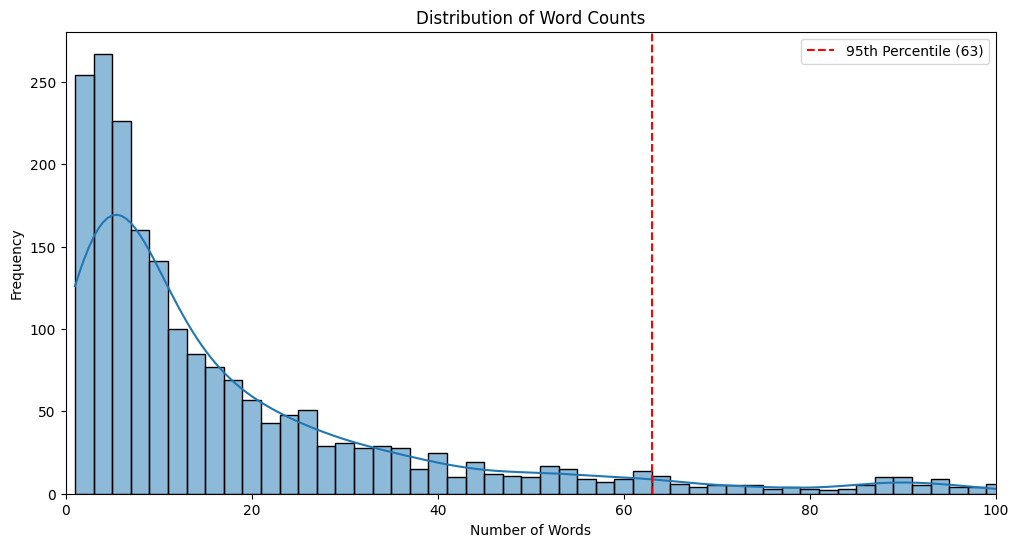

In [21]:
import seaborn as sns
plt.figure(figsize=(12, 6))
sns.histplot(df_2000['word_count'], bins=50, kde=True)
plt.title('Distribution of Word Counts')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.xlim(0, 100)
plt.axvline(p95, color='r', linestyle='--', label=f'95th Percentile ({int(p95)})')
plt.legend()
plt.show()

In [22]:
# Global Content Length
print(df_2000['word_count'].describe())

count    2000.000000
mean       17.829500
std        20.371179
min         1.000000
25%         4.000000
50%        10.000000
75%        23.000000
max       101.000000
Name: word_count, dtype: float64


In [23]:
# Local Content Length
print(df_2000.groupby('score')['word_count'].describe())

# Insights:
# Higher reviews tend to have lower word counts (visible from the
# mean and each quartiles)

        count       mean        std  min   25%   50%   75%    max
score                                                            
1       540.0  25.140741  24.698302  1.0   7.0  16.0  35.0  101.0
2       107.0  30.514019  22.429497  1.0  12.0  25.0  40.5   96.0
3       133.0  26.759398  24.020241  1.0   9.0  19.0  37.0   95.0
4       207.0  20.043478  20.792620  1.0   5.0  13.0  28.0   97.0
5      1013.0  10.967423  13.217993  1.0   3.0   6.0  13.0  100.0


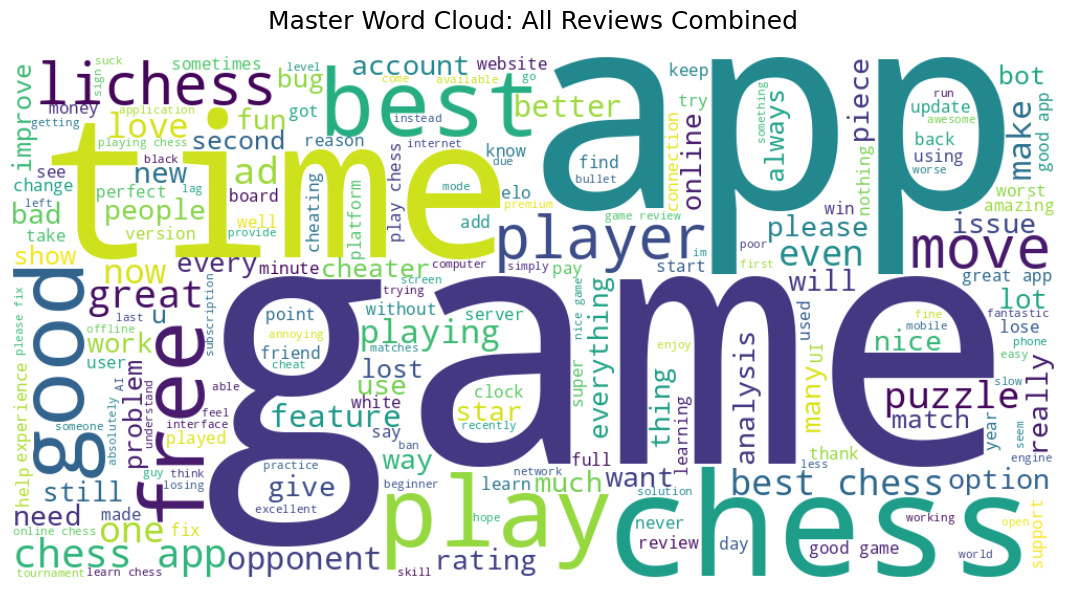

In [24]:
# Global Word Cloud (with stopwords)
from wordcloud import WordCloud, STOPWORDS

all_text = " ".join(df_2000['content'].astype(str))

wordcloud = WordCloud(
  width=1000,
  height=500,
  background_color='white',
  # stopwords=custom_stopwords,
  colormap='viridis',
  min_font_size=10
).generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('Master Word Cloud: All Reviews Combined', fontsize=18, pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()

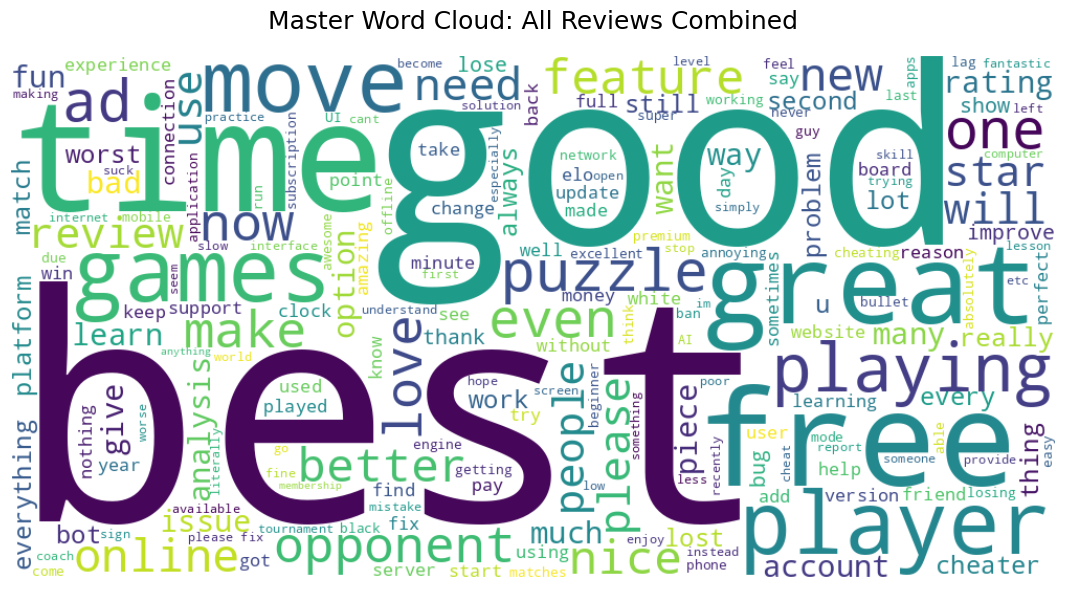

In [25]:
# Global Word Cloud (without stopwords)
from wordcloud import WordCloud, STOPWORDS

all_text = " ".join(df_2000['content'].astype(str))

custom_stopwords = set(STOPWORDS)
custom_stopwords.update(["app", "game", "chess", "play", "lichess", "chesscom"])

wordcloud = WordCloud(
  width=1000,
  height=500,
  background_color='white',
  stopwords=custom_stopwords,
  colormap='viridis',
  min_font_size=10
).generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('Master Word Cloud: All Reviews Combined', fontsize=18, pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()

Word cloud for 1 star reviews:


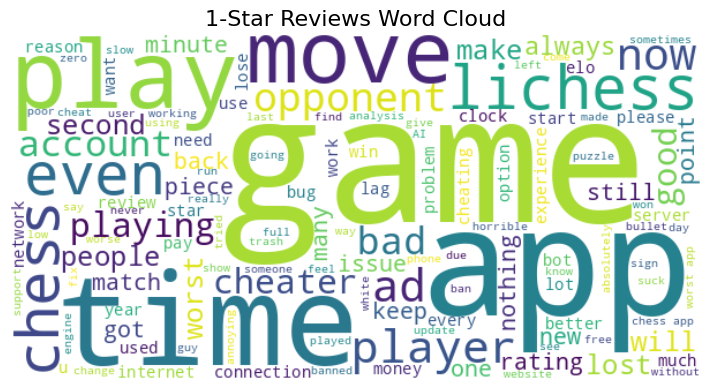

Word cloud for 2 star reviews:


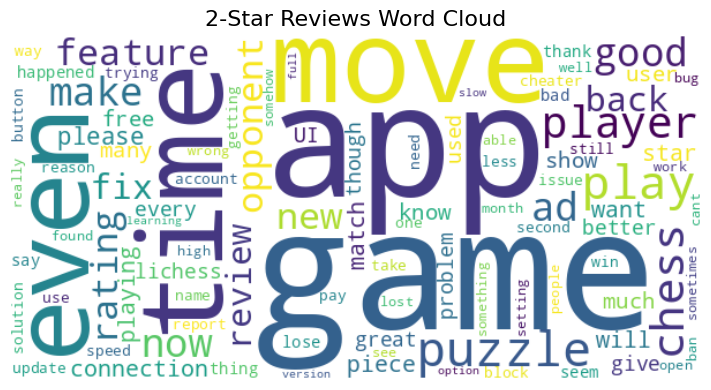

Word cloud for 3 star reviews:


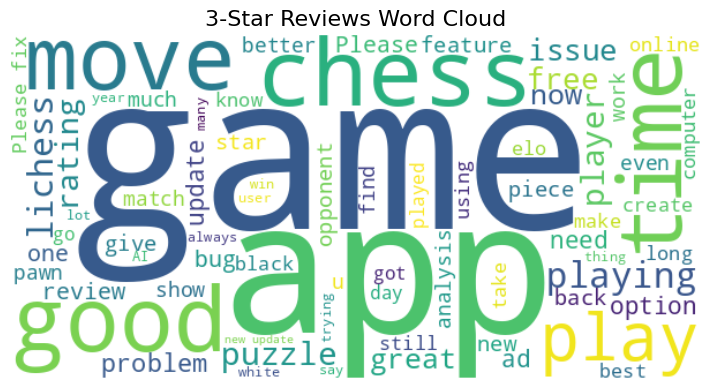

Word cloud for 4 star reviews:


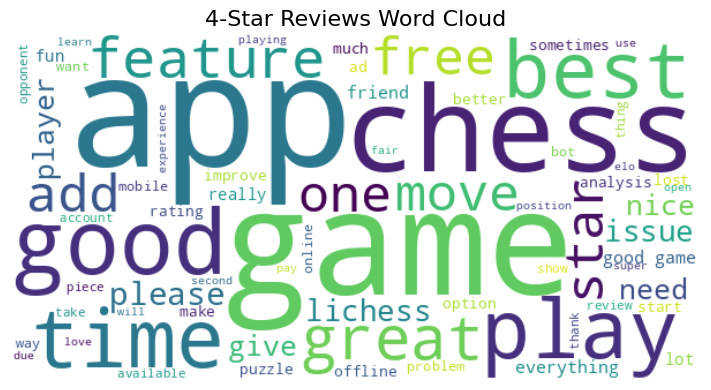

Word cloud for 5 star reviews:


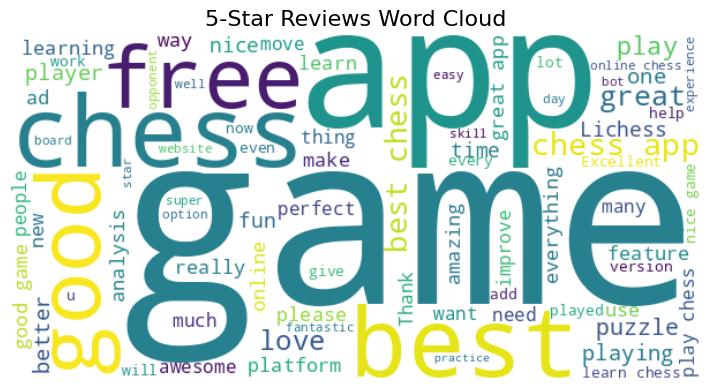

In [26]:
# Local Word Cloud (with stopwords)
def generate_score_wordcloud(df, score):
  print(f"Word cloud for {score} star reviews:")

  text_data = df[df['score'] == score]['content'].astype(str)
  combined_text = " ".join(text_data)

  wordcloud = WordCloud(
      width=600,
      height=300,
      background_color='white',
      # stopwords=stopwords,
      colormap='viridis',
      min_font_size=10
  ).generate(combined_text)

  plt.figure(figsize=(8, 4))
  plt.imshow(wordcloud, interpolation='bilinear')
  plt.title(f'{score}-Star Reviews Word Cloud', fontsize=16)
  plt.axis('off') # Hide axes
  plt.tight_layout()
  plt.show()

for current_score in range(1, 6):
  generate_score_wordcloud(df_2000, current_score)

Word cloud for 1 star reviews:


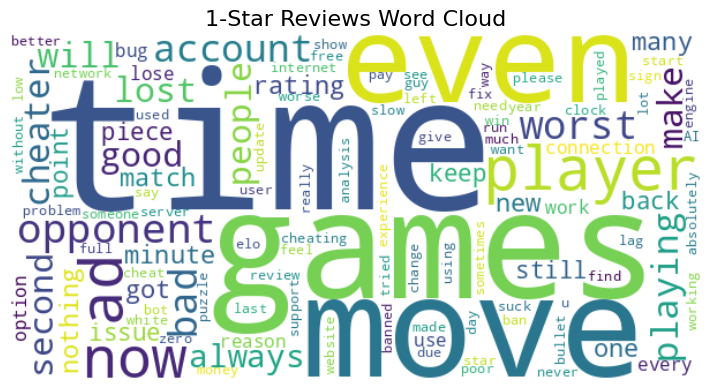

Word cloud for 2 star reviews:


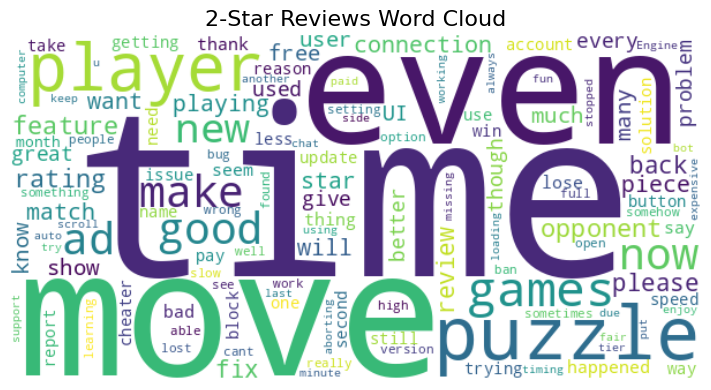

Word cloud for 3 star reviews:


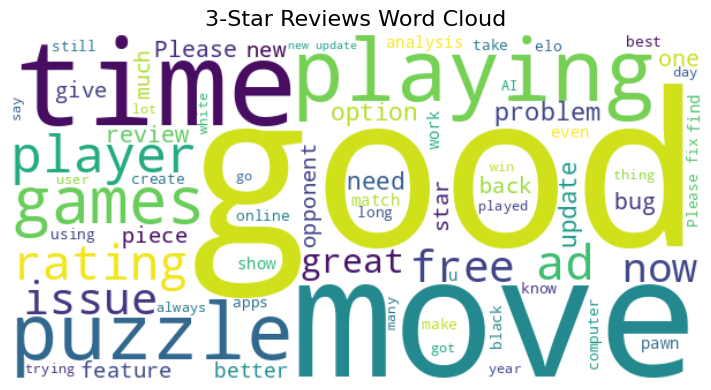

Word cloud for 4 star reviews:


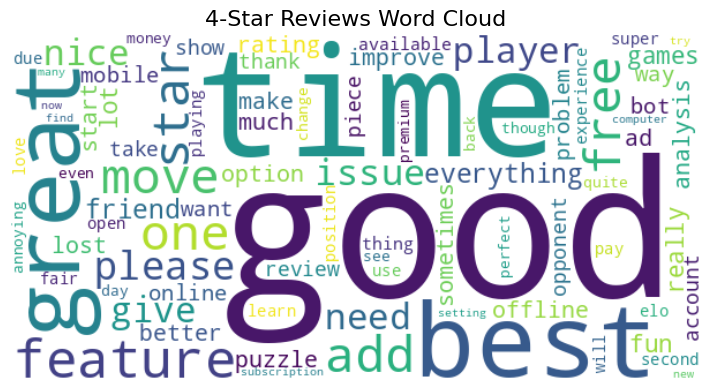

Word cloud for 5 star reviews:


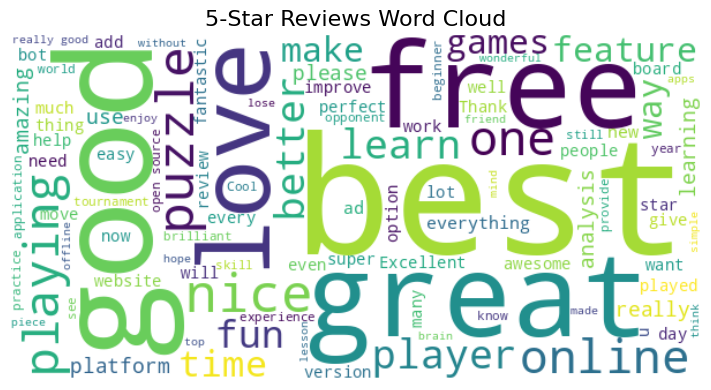

In [27]:
# Local Word Cloud (without stopwords)
def generate_score_wordcloud(df, score, stopwords):
  print(f"Word cloud for {score} star reviews:")

  text_data = df[df['score'] == score]['content'].astype(str)
  combined_text = " ".join(text_data)

  wordcloud = WordCloud(
    width=600,
    height=300,
    background_color='white',
    stopwords=stopwords,
    colormap='viridis',
    min_font_size=10
  ).generate(combined_text)

  plt.figure(figsize=(8, 4))
  plt.imshow(wordcloud, interpolation='bilinear')
  plt.title(f'{score}-Star Reviews Word Cloud', fontsize=16)
  plt.axis('off')
  plt.tight_layout()
  plt.show()

for current_score in range(1, 6):
  generate_score_wordcloud(df_2000, current_score, custom_stopwords)

# Insights:
# Lower ratings: ad
# Higher ratings: best

In [28]:
# Global Top Words
wc = WordCloud()
word_frequencies = wc.process_text(all_text)

top_50 = sorted(word_frequencies.items(), key=lambda x: x[1], reverse=True)[:50]

print("Top 50 most frequent words:")
for word, count in top_50:
  print(f"{word}: {count}")

Top 50 most frequent words:
game: 645
app: 517
time: 223
chess: 219
play: 197
best: 176
good: 176
free: 156
player: 142
move: 139
lichess: 134
chess app: 125
great: 118
ad: 111
puzzle: 110
one: 104
best chess: 99
even: 97
love: 94
now: 93
playing: 90
make: 90
opponent: 86
feature: 78
better: 75
new: 71
need: 68
please: 66
will: 64
people: 63
use: 62
star: 62
rating: 61
want: 60
option: 59
way: 59
give: 59
account: 59
issue: 59
bad: 58
analysis: 57
fun: 57
piece: 57
many: 57
nice: 56
much: 56
really: 56
lot: 53
everything: 51
still: 51


In [29]:
# Local Top Words
def generate_score_wordcloud(df, score):
  text_data = df[df['score'] == score]['content'].astype(str)
  combined_text = " ".join(text_data)

  wc = WordCloud()
  word_frequencies = wc.process_text(combined_text)

  top_50 = sorted(word_frequencies.items(), key=lambda x: x[1], reverse=True)[:50]

  print(f"Top 50 most frequent words for {score} star:")
  for word, count in top_50:
    print(f"{word}: {count}")
  print()

for current_score in range(1, 6):
  generate_score_wordcloud(df_2000, current_score)


# Insights:
# Lower ratings: ad
# Higher ratings: best

Top 50 most frequent words for 1 star:
game: 256
app: 177
time: 119
play: 80
move: 67
lichess: 59
even: 57
chess: 56
player: 54
ad: 52
now: 50
opponent: 47
bad: 41
account: 39
playing: 35
cheater: 35
good: 32
people: 32
make: 31
will: 30
worst: 29
lost: 29
second: 29
always: 28
rating: 28
new: 27
minute: 26
one: 25
match: 24
nothing: 24
many: 24
got: 24
piece: 24
keep: 23
issue: 23
still: 23
point: 23
back: 22
connection: 22
every: 22
bug: 22
work: 21
reason: 21
option: 21
use: 20
lose: 20
cheating: 20
much: 20
need: 20
lot: 20

Top 50 most frequent words for 2 star:
game: 53
app: 46
time: 22
move: 22
even: 18
puzzle: 18
play: 17
chess: 15
player: 14
make: 11
good: 11
now: 11
ad: 11
new: 10
opponent: 10
feature: 10
rating: 10
back: 9
review: 9
fix: 9
please: 9
want: 8
match: 8
piece: 8
playing: 8
will: 8
connection: 8
star: 8
many: 7
much: 7
free: 7
show: 7
know: 7
user: 7
every: 6
give: 6
UI: 6
though: 6
used: 6
great: 6
problem: 6
lichess: 6
better: 6
happened: 6
thing: 6
lose: 6
bad

In [30]:
# Global Unique Words
wc = WordCloud()
word_frequencies = wc.process_text(all_text)

top_50 = sorted(word_frequencies.items(), key=lambda x: x[1])[:50]

print("Top 50 unique words:")
for word, count in top_50:
  print(f"{word}: {count}")

Top 50 unique words:
difference: 1
stronger: 1
Da: 1
iTT: 1
unli: 1
perspective: 1
coded: 1
clueless: 1
protocols: 1
TCP: 1
IP: 1
redesign: 1
genus: 1
egregiously: 1
evaluate: 1
borderline: 1
matched: 1
fabulous: 1
ruined: 1
remark: 1
Firstly: 1
junks: 1
barley: 1
recharge: 1
thirdly: 1
quiting: 1
abundant: 1
limitations: 1
sell: 1
gimmicky: 1
lazy: 1
misleading: 1
mentioned: 1
promoted: 1
yall: 1
cheaper: 1
theoretical: 1
loomis: 1
Prescott: 1
wasting: 1
pagal: 1
ignored: 1
direct: 1
sustained: 1
violation: 1
Googe: 1
requiring: 1
address: 1
timely: 1
manner: 1


In [31]:
# Local Unique Words
def generate_score_wordcloud(df, score):
  text_data = df[df['score'] == score]['content'].astype(str)
  combined_text = " ".join(text_data)

  wc = WordCloud()
  word_frequencies = wc.process_text(combined_text)

  top_10 = sorted(word_frequencies.items(), key=lambda x: x[1])[:10]

  print(f"Top 10 unique words for {score} star:")
  for word, count in top_10:
    print(f"{word}: {count}")
  print()

for current_score in range(1, 6):
  generate_score_wordcloud(df_2000, current_score)

Top 10 unique words for 1 star:
customization: 1
perspective: 1
coded: 1
utterly: 1
clueless: 1
protocols: 1
TCP: 1
IP: 1
redesign: 1
egregiously: 1

Top 10 unique words for 2 star:
yet: 1
costs: 1
yall: 1
cheaper: 1
around: 1
dollars: 1
doesnt: 1
add: 1
highlight: 1
theoretical: 1

Top 10 unique words for 3 star:
tried: 1
ago: 1
moved: 1
chesscom: 1
ruined: 1
nasty: 1
remark: 1
community: 1
hungry: 1
limitations: 1

Top 10 unique words for 4 star:
Technical: 1
glitches: 1
favorite: 1
wasting: 1
nearly: 1
enthusiast: 1
compete: 1
adding: 1
engine: 1
explaining: 1

Top 10 unique words for 5 star:
difference: 1
stronger: 1
Da: 1
iTT: 1
unli: 1
wide: 1
range: 1
genus: 1
matched: 1
rank: 1



In [32]:
df_2000.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   content     2000 non-null   object
 1   score       2000 non-null   int64 
 2   word_count  2000 non-null   int64 
 3   char_count  2000 non-null   int64 
 4   contracted  2000 non-null   object
dtypes: int64(3), object(2)
memory usage: 78.3+ KB


In [33]:
df_final = df_2000[['contracted', 'score']].copy()

In [34]:
df_final.rename(columns={'contracted':'content'}, inplace=True)

In [35]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  2000 non-null   object
 1   score    2000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 31.4+ KB


In [36]:
df_final.to_csv('imbalanced_cleaned.csv')